<a href="https://colab.research.google.com/github/aryanalavade/college-student-financial-preparedness/blob/main/notebooks/financial_preparedness_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The College Student Financial Preparedness Blueprint: Predicting Emergency Savings Through Financial Habits

1.   List item
2.   List item


**Your name:** Arya Nalavade  |  **Starter dataset or your own?** [Starter / Own]

---

## How to use this template
- **Make a copy** (File > Save a copy in Drive) before you start.
- Every section marked **REQUIRED** must be filled in. That's what makes your project complete.
- Sections marked **OPTIONAL** are ways to make your project shine. Skip them if you're short on time.
- Sections 1-3 come straight from your Checkpoint 3 answers. Copy them in and update anything that changed.

### Minimum viable project checklist
A complete project has all of these:
- [ ] One dataset (Section 2)
- [ ] One model compared against a baseline (Sections 5-7)
- [ ] One evaluation metric (Section 7)
- [ ] A fairness check (Section 8)
- [ ] Every REQUIRED section of this template filled in
- [ ] Slides (15 or fewer) and a 5-7 minute video (Section 13)

---
## Agreement for written sections
By filling in the written sections of this notebook (Sections 1, 9, 10, and 11), you confirm that **you did not use AI tools or large language models (LLMs) to write their text**. These sections should be your own reasoning in your own words. AI use anywhere else should be recorded in Section 12.

---
## 1. Research question (REQUIRED)
**Instructions:** In 1-3 sentences, what finance question are you answering, and who would care about the answer?

I am looking to answer which financial habits and educational experiences are associated with having enough financial independence among young adults aged 18–34. In this project, financial independence is defined as having enough emergency savings to cover three months of expenses. College students, universities, and other financial education organizations could use these findings to identify gaps in financial preparedness and acquire or develop better resources to help young adults build financial security.

**What I'm predicting (target variable):** J5, whether a respondant has enough emergency savings to cover three months of expense

**Is this a classification problem (predicting a category) or a regression problem (predicting a number)?** Classification

---
## 2. Dataset (REQUIRED)
**Instructions:** Fill in the table. If you used more than one dataset, add a row for each.

| Dataset name | Link / source | # of rows | Why I chose it |
|---|---|---|---|
| 2024 National Financial Capability Study (NFCS) – State-by-State Survey | https://finrafoundation.org/nfcs-data-and-downloads | 25,539 | I chose this dataset because it includes survey data for financial behaviors, financial knowledge, and emergency savings. |

In [2]:
# Load your data.
import pandas as pd


# Option B: your own CSV file. Replace the path below.
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

df.head()

Saving NFCS 2024 State Data 250623.csv to NFCS 2024 State Data 250623.csv


,NFCSID,STATEQ,CENSUSDIV,CENSUSREG,A50A,A3Ar_w,A50B,A4A_new_w,A5_2015,A6,...,M6,M7,M8,M31,M50,M9,M10,wgt_n2,wgt_d2,wgt_s3
0,2024010001,36,3,2,2,3,9,1,6,1,...,1,3,98,98,98,1,2,1.153548,1.123949,0.859644
1,2024010002,48,9,4,1,6,6,1,5,5,...,1,3,98,3,3,1,2,1.398688,0.863440,0.975078
2,2024010003,38,9,4,1,6,6,1,4,1,...,1,3,1,98,98,2,2,1.398688,0.472645,0.893974
3,2024010004,48,9,4,2,6,12,1,7,1,...,1,3,1,4,98,1,2,1.250293,0.614156,0.778748
4,2024010005,44,7,3,2,6,12,2,7,4,...,1,3,2,3,2,1,1,1.250076,2.228957,0.783507


---
## 3. Data cleaning (REQUIRED)
**Instructions:** Clean your data in the code cell below (for example: fill or drop missing values, drop columns you don't need, convert text categories to numbers). Then list what you changed and why.

1. Removed duplicate respondents: Dropped duplicate records using the NFCSID identifier to ensure each respondent was represented only once
2. Removed the respondent ID: Dropped NFCSID because it is a unique identifier
3. Converted selected variables to numeric: Converted the project variables (J5, M20, B43, J3, and M4) to numeric data types to support statistical analysis and machine learning
4. Handled special survey response codes: Replaced responses coded as 98 and 99 with missing values because they represent non-substantive responses rather than meaningful answers
5. Removed respondents with missing target values: Dropped respondents without a valid response to J5, our target variable, because their emergency savings status could not be determined.
6. Filtered the population to young adults aged 18–34: Selected respondents in age categories 1 and 2 of A3Ar_w to align the dataset with the project's target age group


In [3]:

# check for missing values and data types first
df.info()

# remove duplicate respondents
df = df.drop_duplicates(subset="NFCSID")

# remove the respondent ID because it is not a meaningful predictor
df = df.drop(columns=["NFCSID"])

# identify variables used in the project
project_variables = ["J5", "M20", "B43", "J3", "M4"]

# convert blank responses to missing values and ensure numeric format
for column in project_variables:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# replace special survey response codes with missing values
df[project_variables] = df[project_variables].replace(
    {98: float("nan"), 99: float("nan")}
)

# remove respondents without a valid emergency savings response
df = df.dropna(subset=["J5"])

# filter the dataset to respondents aged 18-34
df = df[df["A3Ar_w"].isin([1, 2])]

# display cleaning results
print("Dataset dimensions after cleaning:", df.shape)

print("\nMissing values in project variables:")
print(df[project_variables].isnull().sum())

# display the distribution of emergency savings responses
print("\nEmergency savings response distribution:")
print(df["J5"].value_counts())
print(df["J5"].value_counts(normalize=True) * 100)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25539 entries, 0 to 25538
Columns: 133 entries, NFCSID to wgt_s3
dtypes: float64(3), int64(86), object(44)
memory usage: 25.9+ MB
Dataset dimensions after cleaning: (6083, 132)

Missing values in project variables:
J5       0
M20    477
B43    146
J3     205
M4     114
dtype: int64

Emergency savings response distribution:
J5
2.0    3830
1.0    2253
Name: count, dtype: int64
J5
2.0    62.962354
1.0    37.037646
Name: proportion, dtype: float64


---
## 4. Exploring the data (REQUIRED)
**Instructions:** Include at least one chart from your EDA (you can reuse your Checkpoint 3 work). Under it, write 1-2 sentences about what it shows.



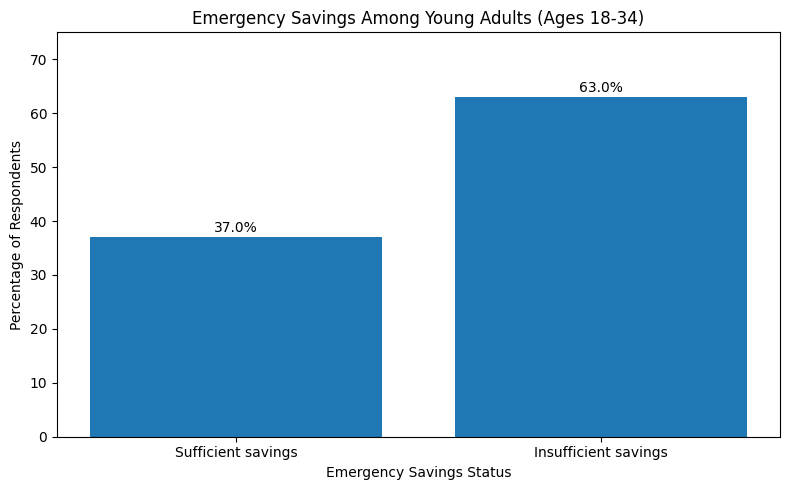

In [4]:
# TODO: make at least one chart (for example, a histogram, box plot, or bar chart of your target variable).

import matplotlib.pyplot as plt

# calculate the percentage of respondents in each savings category
savings_percentages = df["J5"].value_counts(normalize=True).reindex([1, 2]) * 100

# create the bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(
    ["Sufficient savings", "Insufficient savings"],
    savings_percentages
)

# add percentage labels above each bar
for bar, percentage in zip(bars, savings_percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{percentage:.1f}%",
        ha="center"
    )

# format the chart
plt.title("Emergency Savings Among Young Adults (Ages 18-34)")
plt.xlabel("Emergency Savings Status")
plt.ylabel("Percentage of Respondents")
plt.ylim(0, 75)
plt.tight_layout()
plt.show()


The bargraph chart shows that only about 37.0% of respondents aged 18–34 have enough emergency savings to cover at least three months of expenses, while 63.0% do not. This shows us that a majority of young adults in the survey lack sufficient emergency savings, which highlights the importance of understanding which financial habits and educational experiences are associated with financial preparedness.

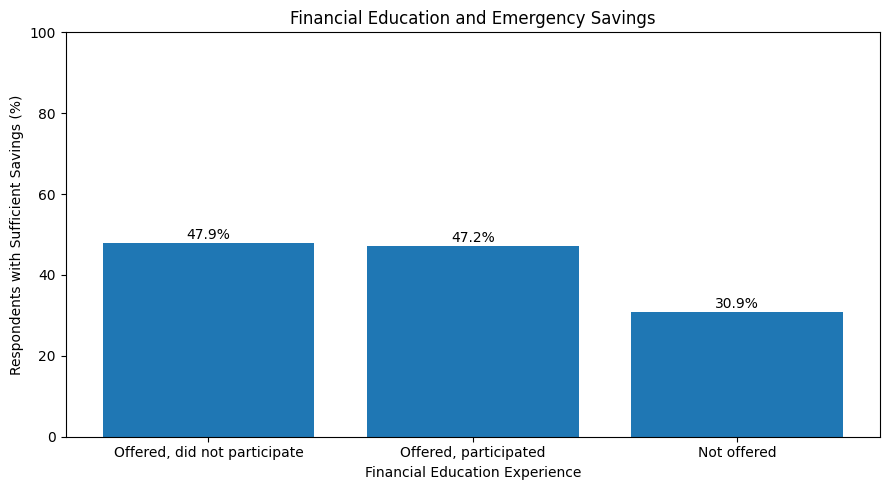

In [5]:

# distribution of emergency funds across people who were offered but did not participate, offered and did participate, and not offered financial education
# calculate the percentage with sufficient savings for each financial education category
education_savings = pd.crosstab(
    df["M20"],
    df["J5"],
    normalize="index"
) * 100

# select respondents with sufficient emergency savings
sufficient_savings = education_savings[1]

# define category labels
labels = {
    1: "Offered, did not participate",
    2: "Offered, participated",
    3: "Not offered"
}

# create the bar chart
plt.figure(figsize=(9, 5))
bars = plt.bar(
    [labels[i] for i in sufficient_savings.index],
    sufficient_savings.values
)

# add percentage labels above each bar
for bar, percentage in zip(bars, sufficient_savings.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{percentage:.1f}%",
        ha="center"
    )

# format the chart
plt.title("Financial Education and Emergency Savings")
plt.xlabel("Financial Education Experience")
plt.ylabel("Respondents with Sufficient Savings (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0, ha="center")
plt.tight_layout()
plt.show()


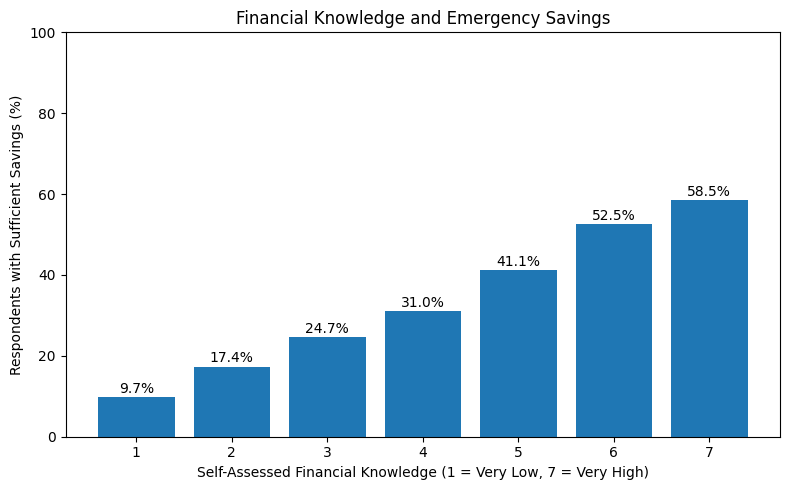

In [6]:
# Financial knowledge VS emergency savings
# calculate the percentage with sufficient savings at each knowledge level
knowledge_savings = df.groupby("M4")["J5"].apply(
    lambda x: (x == 1).mean() * 100
)

# create the bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(knowledge_savings.index, knowledge_savings.values)

# add percentage labels
for bar, percentage in zip(bars, knowledge_savings.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{percentage:.1f}%",
        ha="center"
    )

# format the chart
plt.title("Financial Knowledge and Emergency Savings")
plt.xlabel("Self-Assessed Financial Knowledge (1 = Very Low, 7 = Very High)")
plt.ylabel("Respondents with Sufficient Savings (%)")
plt.xticks(range(1, 8))
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

---
## 5. Train/test split and baseline (REQUIRED)
A **baseline** is the simplest possible guess. If your model can't beat it, the model isn't adding much. Run the cell below as-is after filling in your features and target.
- For **classification**, the baseline always predicts the most common category.
- For **regression**, the baseline always predicts the average.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier, DummyRegressor

# TODO: list your feature columns and your target column.
features = ["M20", "M4", "B43", "J3"]
target = "J5"

X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Classification baseline: always predict the most common category.
baseline = DummyClassifier(strategy="most_frequent")
# Regression baseline: delete the line above and use this one instead.
# baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
print("Baseline is ready. You'll compare it to your model in Section 7.")

Baseline is ready. You'll compare it to your model in Section 7.


---
## 6. Model (REQUIRED: at least one)
**Instructions:** Train at least one model you learned in the challenge (linear regression, logistic regression, decision tree, or random forest). Then fill in the summary.

#### Model 1
* **Model type:** Logistic Regression
* **Features used:** M20 (financial eduation), M4 (self-assessed financial knowledge), B43 (financial management tools), and J3 (spending relative to income)
* **Why I chose this model:** Logistic Regression is effective for predicting a binary outcome. It also will provide interpretable coefficients that will help identify which financial factors are associated with sufficient emergency savings.

In [10]:
# TODO: train your model. Example for a decision tree:
# train a logistic regression model
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

#### Model 2, 3, ... (OPTIONAL)
Copy the Model 1 summary and code cell for each extra model.

#### Model 1
* **Model type:** Decision Tree Classifier
* **Features used:** M20 (financial eduation), M4 (self-assessed financial knowledge), B43 (financial management tools), and J3 (spending relative to income)
* **Why I chose this model:** A decision tree can capture nonlinear relationships and interactions between financial factors. This allows us to compare its predictive performance with Logistic Regression.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

# train a decision tree model
model_2 = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    DecisionTreeClassifier(max_depth=4, random_state=42)
)

model_2.fit(X_train, y_train)
y_pred_2 = model_2.predict(X_test)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


#### Model 3
* **Model type:** Random Forest Classifier
* **Features used:** M20 (financial eduation), M4 (self-assessed financial knowledge), B43 (financial management tools), and J3 (spending relative to income)
* **Why I chose this model:** Since the decision tree performed well, using multiple trees will allow for combining multiple predictions and therefore potentially improved predictive performance.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

# train a random forest model
model_3 = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    RandomForestClassifier(n_estimators=100, random_state=42)
)

model_3.fit(X_train, y_train)
y_pred_3 = model_3.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


---
## 7. Evaluation (REQUIRED)
**Instructions:** Pick one metric that fits your question and compare your model to the baseline.
- Classification: accuracy, precision, recall, or F1. If one category is rare (like fraud or default), accuracy can be misleading, so also look at recall or F1.
- Regression: RMSE or R-squared.

| Model | Metric: F1-score |
|---|---|
| Baseline | 0.000 |
| Logistic Regression | 0.462 |
| Decision Tree Classifier | 0.525 |
| Random Forest | 0.499 |

**Does your model beat the baseline? By how much, and does that difference matter for your question?**

Yes, the logistic regression model beats the baseline by achieving an F1-score of 0.462 compared to 0.000. Its accuracy also improved from 62.9% to 67.2%. This indicates that model provides value beyond simply predicting th emost common category and can identify respondent the survey responders with sufficient emergency savings. After testing out the decision tree classfier, it performed even better, with an F1-score of 0.525 and an accuracy of 67.6%. This suggests that capturing nonlinear relationships between financial factors may improve predictions of emergency savings preparedness. Finally, the Random Forest classifier achieved an F1-score of 0.499 and an accuracy of 67.5%. However, even though it performed better than the Logistic Regression, it did not surpass the Decision Tree classifier. This suggests that combining multiple decision trees did not further improve predictive performance for this dataset.

In [17]:
from sklearn.metrics import accuracy_score, f1_score

# calculate accuracy
print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 3))
print("Linear Regression accuracy:   ", round(accuracy_score(y_test, y_pred), 3))

# calculate f1-score for sufficient emergency savings (class 1)
print("\nBaseline F1-score:", round(f1_score(y_test, baseline_pred, pos_label=1), 3))
print("Linear Regression F1-score:   ", round(f1_score(y_test, y_pred, pos_label=1), 3))

Baseline accuracy: 0.629
Linear Regression accuracy:    0.672

Baseline F1-score: 0.0
Linear Regression F1-score:    0.462


In [14]:
# calculate accuracy and f1-score
print("Decision Tree accuracy:", round(accuracy_score(y_test, y_pred_2), 3))
print("Decision Tree F1-score:", round(f1_score(y_test, y_pred_2, pos_label=1), 3))

Decision Tree accuracy: 0.676
Decision Tree F1-score: 0.525


In [16]:
# calculate accuracy and f1-score
print("Random Forest accuracy:", round(accuracy_score(y_test, y_pred_3), 3))
print("Random Forest F1-score:", round(f1_score(y_test, y_pred_3, pos_label=1), 3))

Random Forest accuracy: 0.675
Random Forest F1-score: 0.499


---
## 8. Fairness check (REQUIRED)
**Instructions:** Choose one column that describes a group of people (for example: sex, age group, race, marital status). Check whether your model performs equally well for each group. You don't need to include that column as a feature to check it.

**Group column I checked:** A4A_new_w (Ethnicity)

**What I found (2-3 sentences):** The decision tree model performed slightly better for suvery responders who were white, but not hispanic, and it had a 68.6% accuracy. The other group, who were non-white survey responders, had a 66.5% accuracy. Although the gap is small, it shows that the non-white survery responders could be at a disadvantage when using this model since the accuracy is slightly lower for their group, and therefore potentially lead to less appropriate recommmedations.

In [18]:
# TODO: set the column that describes the groups you want to compare.
group_col = "A4A_new_w"

groups = df.loc[X_test.index, group_col]

for g in groups.unique():
    mask = (groups == g).values
    acc = accuracy_score(y_test[mask], y_pred_2[mask])
    print(f"{g}: n = {mask.sum()}, accuracy = {acc:.3f}")

1: n = 641, accuracy = 0.686
2: n = 576, accuracy = 0.665


---
## 9. Limitations (REQUIRED)
**Instructions:** In 3-5 sentences: What can't your data or model tell you? What's missing from the data, and what would you do with more time?


The analysis is limited by reporting bias in the dataset being used. Since the dataset uses survey responses, which are self-reported, they could contain biases and inaccuracies. Additionally, this dataset combines multiple races and ethnic groups into a single category, which makes it difficult to evaluate the model's performance across specific racial groups. The model also uses only four factors to influence its predictions. With additional time, I would look into finding larger datasets that contain more predictors to train my model, as well as data with more detailed demographics, so I can evaluate fairness across a wider range of racial groups.



---
## 10. Results (REQUIRED)
**Instructions:** In 5-10 sentences, explain what you found. Refer to your metric, the baseline, and your fairness check.

This project explored whether how financial knowledge and how people manage money can help predict if college students between the ages of 18 and 24 have enough emergency savings to cover three months of expenses. The baseline model had an accuracy of 62.9% and an F1-score of 0.000 which shows that just predicting the common group did not help identify responders who had enough emergency savings. Logistic Regression did better with a 67.2% accuracy and a 0.462 F1-score. The Decision Tree performed the best with a 67.6% accuracy and a 0.525 F1-score, suggesting that it captured patterns in the data that the linear model may have missed. The last model I tested was the Random Forest, which had a 67.5% accuracy and a 0.499 F1-score, slightly lower than the F1-score of the Decision Tree model. Overall the Decision Tree gave the balance between accuracy and F1-score among all the models tested. When checking for fairness the Decision Tree had 68.6% accuracy for White non-Hispanic respondents and 66.5% for Non-White respondents, which is a small difference of 2.1 percentage points. These results show that financial knowledge and money-management habits have some information, for predicting emergency savings and can be used to help inform financial education initiatives. However, given the model's limitations, its predictions should be used as guidance rather than as the basis for high-stakes financial decisions.


---
## 11. Conclusion and recommendations (REQUIRED)
**Instructions:** In 5-8 sentences: What should a bank, lender, regulator, or customer do with your findings?

Colleges, universities and student financial literacy organizations could use these findings to understand the financial behaviors that come with having sufficient emergency savings among young adults. They could design targeted financial education programs that highlight budgeting, saving habits and the improvement of knowledge. For example universities could set up financial awareness workshops while student organizations could lead peer discussions and supply tools for building emergency funds. Banks might also use these insights to create student‑focused budgeting tools, savings goal trackers and other educational resources. The model should serve as a supplementary guide for educational efforts, rather than to make assumptions about individual students' financial situations. Organizations must also weigh differences and the limits of the data when applying these findings. In the end these insights can make financial education more relevant and easier to reach for adults as they develop financial independence.

---
## 12. AI-use log (REQUIRED)
**Instructions:** List each way you used AI tools (chatbots, code assistants, etc.). If you didn't use any, write "None."

| Tool | What I used it for | How I checked the output |
|---|---|---|
| Claude| I researched differencet machine learning models that were suitable for my dataset, and compared their advantages and disadvantages. Additionally I used it to help dubugging my code and fixing errors.| I reviewed the explainations it gave and the cross validated using other resources that the suggested models and information were valid and appropriate. Following that, when I begin coding my models I also verified the model's metrics and output for further validation. |

---
## 13. Slides, video, and references (REQUIRED)
- **Slides (15 or fewer):** [link]
- **Video (5-7 minutes):** [link]

**References:** Links to any articles or resources you used to interpret results or make recommendations.
1. [Reference 1 with link]
2. [...]

---
## Make it shine (OPTIONAL)
Ideas if you have extra time: compare 2-3 models, tune a model (for example, `max_depth`), show feature importance, combine two datasets, or add a confusion matrix. See "Tips to Make Your Project Shine" on the challenge homepage.

### Feature Importance for the Decision Tree Model

  Feature  Importance
1      M4    0.451697
3      J3    0.443436
0     M20    0.092079
2     B43    0.012788


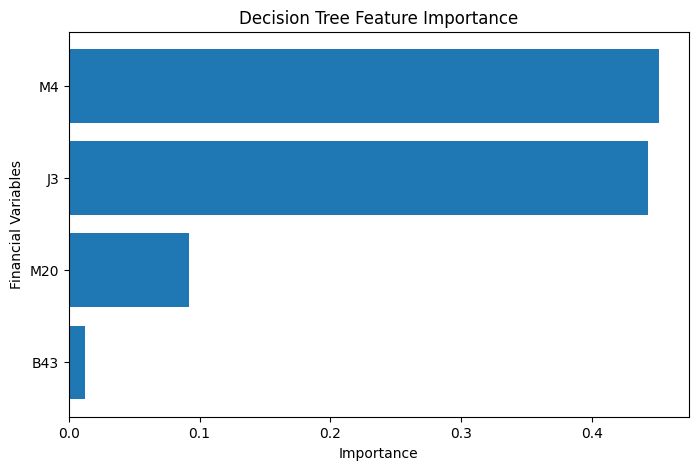

In [22]:
# get the Decision Tree classifier from the pipeline
tree = model_2.named_steps['decisiontreeclassifier']

# calculate feature importance
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tree.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print(importance)

# visualize feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.ylabel("Financial Variables")
plt.title("Decision Tree Feature Importance")
plt.gca().invert_yaxis()
plt.show()

The feature importance highlights that the M4 (self-assessed financial knowledge) and J3 (spending relative to income) variables have the greatest influence on the model's predictions. On the otherside, B43 (financial management tools) has neglible influence on the model.

In [23]:
### Confusion Matrix for the Decision Tree Model

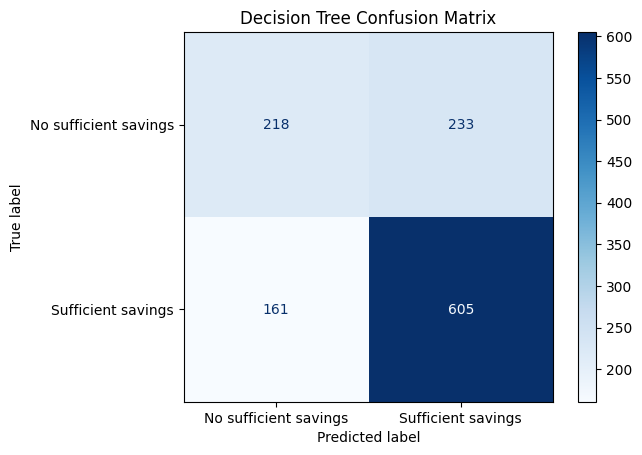

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# create confusion matrix
cm = confusion_matrix(y_test, y_pred_2)

# display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No sufficient savings", "Sufficient savings"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Decision Tree Confusion Matrix")
plt.show()

The confusion matrix highlights that the model correctly classifed 823 out of the 1217 respondents. This matrix also shows us that the model performs better for identifying students who loack sufficient emergency savings.

Tuned Decision Tree AUC: 0.687


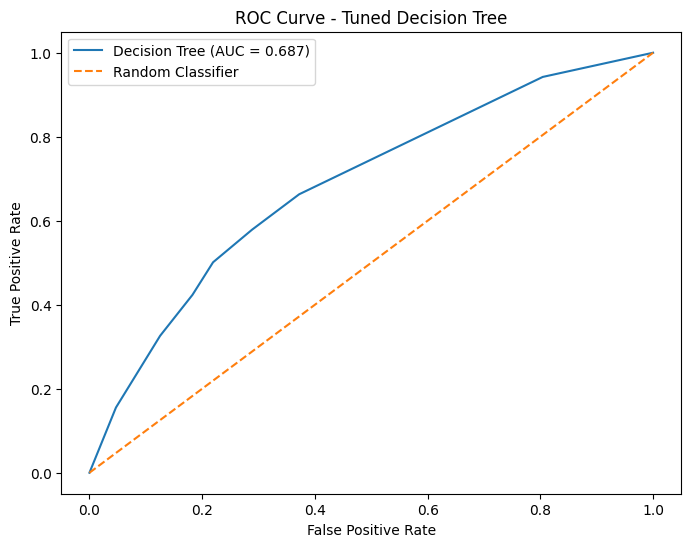

In [35]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# convert the Class 1 into the positive class (1 = sufficient savings)
y_test_binary = (y_test == 1).astype(int)

# get the predicted probabilities for Class 1
y_prob = best_model.predict_proba(X_test)[:, 0]

# calculate the  ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)

auc = roc_auc_score(y_test_binary, y_prob)

print("Tuned Decision Tree AUC:", round(auc, 3))

# plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Decision Tree")
plt.legend()
plt.show()